## EDA


In [1]:
# Installing Required Python Libraries


!pip install numpy
!pip install pandas
!pip install scikit-learn
!pip install matplotlib
!pip install seaborn
!pip install joblib

!pip install spacy
!pip install pyldavis
!pip install language_tool_python
!pip install skll
!pip install keras
!pip install tensorflow
!pip install scikeras

In [2]:
#TODO - Replace the training dataset with the Converetd Audio Dataset

import pandas as pd
training_data  = pd.read_csv('training_data.tsv', sep='\t', encoding = "ISO-8859-1")\
            .rename(columns={'essay_set': 'topic', 'domain1_score': 'target_score', 'domain2_score': 'topic2_target'})

training_data.sample()

training_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12974 entries, 0 to 12973
Data columns (total 28 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   essay_id        12974 non-null  int64  
 1   topic           12974 non-null  int64  
 2   essay           12974 non-null  object 
 3   rater1_domain1  12974 non-null  int64  
 4   rater2_domain1  12974 non-null  int64  
 5   rater3_domain1  128 non-null    float64
 6   target_score    12974 non-null  int64  
 7   rater1_domain2  1800 non-null   float64
 8   rater2_domain2  1800 non-null   float64
 9   topic2_target   1800 non-null   float64
 10  rater1_trait1   2292 non-null   float64
 11  rater1_trait2   2292 non-null   float64
 12  rater1_trait3   2292 non-null   float64
 13  rater1_trait4   2292 non-null   float64
 14  rater1_trait5   723 non-null    float64
 15  rater1_trait6   723 non-null    float64
 16  rater2_trait1   2292 non-null   float64
 17  rater2_trait2   2292 non-null  

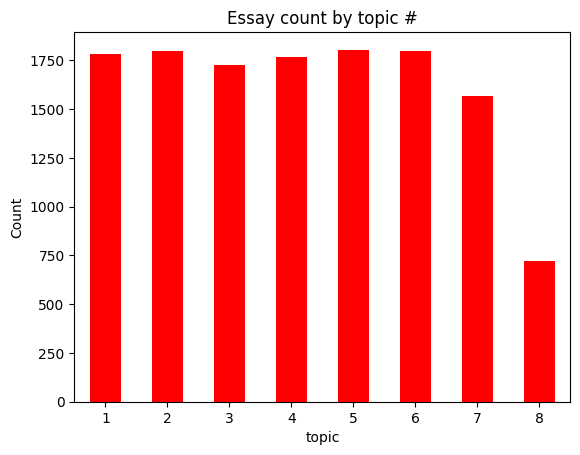

In [3]:
import matplotlib.pyplot as plt

training_data.groupby('topic').agg('count').plot.bar(y='essay', rot=0, legend=False, color = 'red')
plt.title('Essay count by topic #')
plt.ylabel('Count')
plt.show()

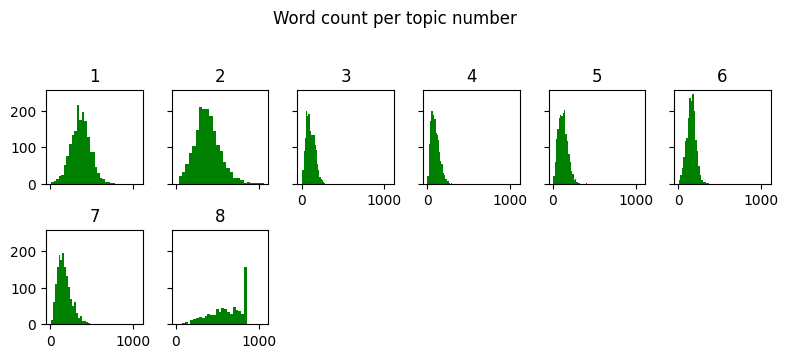

In [4]:
# Count characters and words for each essay
training_data['word_count'] = training_data['essay'].str.strip().str.split().str.len()

training_data.hist(column='word_count', by='topic', bins=25, sharey=True, sharex=True, layout=(3, 6), figsize=(8,5), rot=0, color = 'green')
plt.suptitle('Word count per topic number')
plt.xlabel('Number of words in essay')
plt.tight_layout(rect=[0, 0.04, 1, 0.96])
plt.show()

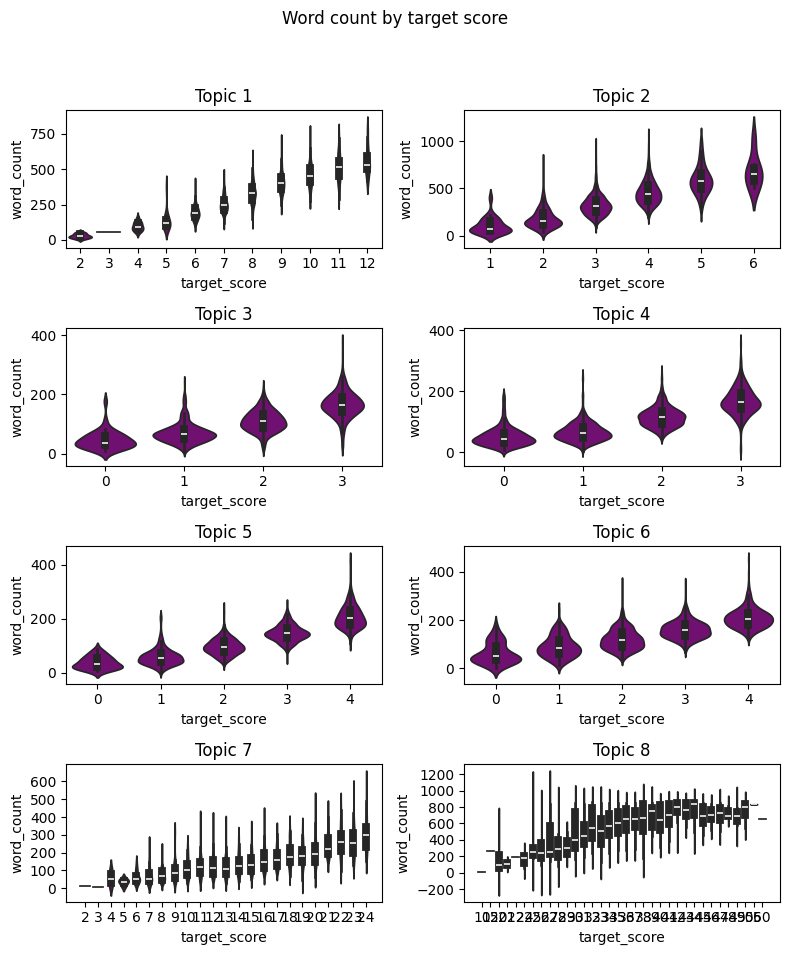

In [5]:
import seaborn as sns

#Get word count by score using the topic and target_score features
training_data.groupby(['topic'])['target_score'].agg(['min','max','count','nunique'])

topic_number = 0
fig, ax = plt.subplots(4,2, figsize=(8,10))
for i in range(4):
    for j in range(2):
        topic_number += 1
        sns.violinplot(x='target_score', y='word_count', data=training_data[training_data['topic'] == topic_number], ax=ax[i,j], color = 'purple')
        ax[i,j].set_title('Topic %i' % topic_number)
ax[3,0].locator_params(nbins=10)
ax[3,1].locator_params(nbins=10)
plt.suptitle('Word count by target score')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

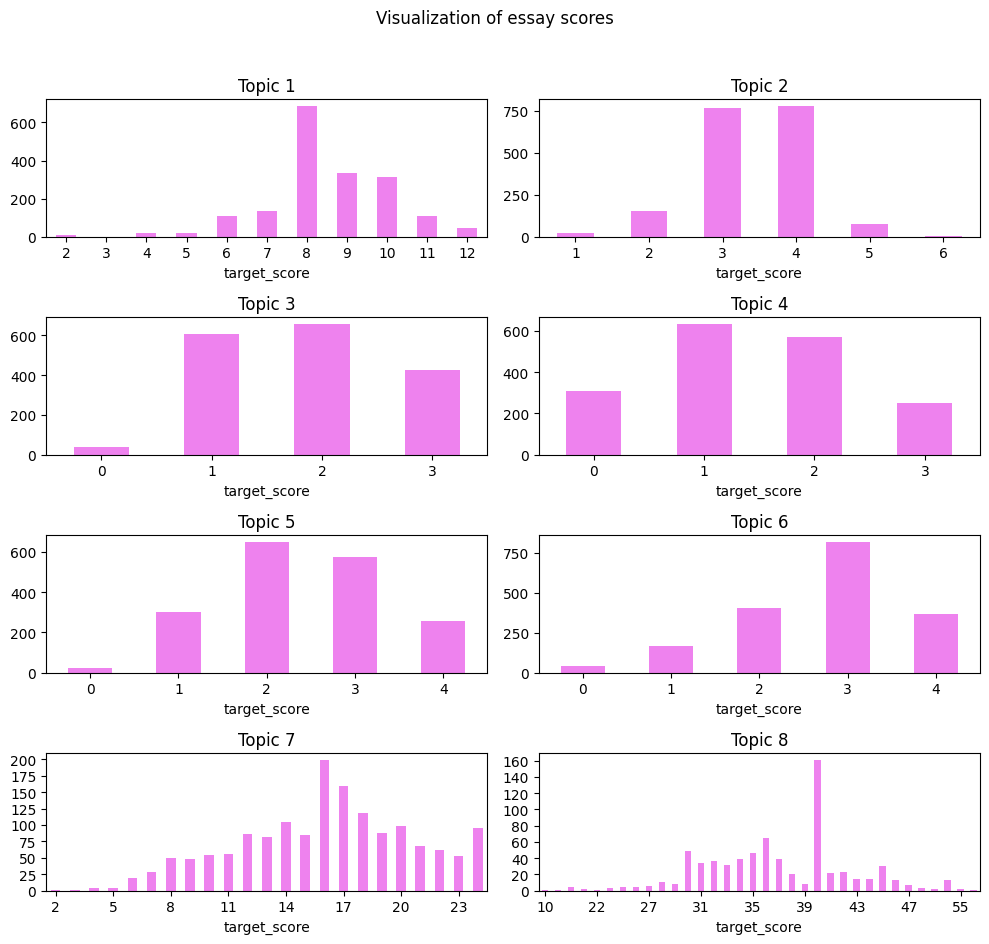

In [6]:
#Visualization of the essay scores
topic_number = 0
fig, ax = plt.subplots(4,2, figsize=(10,10), sharey=False)
for i in range(4):
    for j in range(2):
        topic_number += 1
        training_data[training_data['topic'] == topic_number]\
            .groupby('target_score')['essay_id']\
            .agg('count')\
            .plot.bar(ax=ax[i, j], rot=0, color = 'violet')
        ax[i,j].set_title('Topic %i' % topic_number)
ax[3,0].locator_params(nbins=10)
ax[3,1].locator_params(nbins=10)
plt.suptitle('Visualization of essay scores')
plt.tight_layout(rect=[0, 0.04, 1, 0.96])
plt.show()


### Language Correction

In [7]:
text = 'I an takung TOEFL examm instaed of IELTS'

from textblob import TextBlob
data = TextBlob(text)
print (data.correct())

I an taking TOEFL exam instead of IELTS


In [8]:
# From our observation textblob is not so accurate so using language_tool_python instead

import language_tool_python
tool = language_tool_python.LanguageTool('en-US')

matches = tool.check(text)
tool.correct(text)


text = training_data.essay[80]
text

matches = tool.check(text)
tool.correct(text)

In [ ]:
training_data['matches'] = training_data['essay'].apply(lambda txt: tool.check(txt))
training_data['corrections'] = training_data.apply(lambda l: len(l['matches']), axis=1)
training_data['corrected'] = training_data.apply(lambda l: tool.correct(l['essay']), axis=1)

# saving corrected dataset
training_data.to_pickle('training_corrected.pkl')


print('Orginial Statement From Essay:', training_data.essay[100])
print('Corrected Statment with language_tool_python:',training_data.corrected[100])

### Tokenizing

In [9]:
import spacy
from spacy.lang.en.stop_words import STOP_WORDS
from string import punctuation

In [10]:
training_data = pd.read_pickle('training_corrected.pkl')

stop_words = set(STOP_WORDS)
stop_words.update(punctuation)

In [ ]:
sentences = []
tokens = []
lemmatizedtokens = []
partsofspeech = []
nouns = []

# Loading the spaCy English language model pipeline for text processing using small model
nlp = spacy.load('en_core_web_sm')


for essay in nlp.pipe(training_data['corrected'], batch_size=100):
    if essay.is_parsed:
        tokens.append([e.text for e in essay])
        sentences.append([sent.text.strip() for sent in essay.sents])
        partsofspeech.append([e.pos_ for e in essay])
        nouns.append([e.text for e in essay.ents])
        lemmatizedtokens.append([n.lemma_ for n in essay])
    else:
        tokens.append(None)
        lemmatizedtokens.append(None)
        partsofspeech.append(None)
        sentences.append(None)
        nouns.append(None)

training_data['tokens_sm'] = tokens
training_data['lemmatizedtokens_sm'] = lemmatizedtokens
training_data['partsofspeech_sm'] = partsofspeech
training_data['sentences_sm'] = sentences
training_data['nouns_sm'] = nouns

training_data[['tokens_sm', 'lemmatizedtokens_sm', 'partsofspeech_sm', 'sentences_sm', 'nouns_sm']].head()

training_data.to_pickle('training_spacy_sm.pkl')

training_data = pd.read_pickle('training_spacy_sm.pkl')


In [ ]:
sentences = []
tokens = []
lemmatizedtokens = []
partsofspeech = []
nouns = []

!python -m spacy download en_core_web_md

# Loading the spaCy English language model pipeline for text processing using medium model
nlp = spacy.load('en_core_web_md')


for essay in nlp.pipe(training_data['corrected'], batch_size=100):
    if essay.is_parsed:
        tokens.append([e.text for e in essay])
        sentences.append([sent.text.strip() for sent in essay.sents])
        partsofspeech.append([e.pos_ for e in essay])
        nouns.append([e.text for e in essay.ents])
        lemmatizedtokens.append([n.lemma_ for n in essay])
    else:
        tokens.append(None)
        lemmatizedtokens.append(None)
        partsofspeech.append(None)
        sentences.append(None)
        nouns.append(None)

training_data['tokens_md'] = tokens
training_data['lemmatizedtokens_md'] = lemmatizedtokens
training_data['partsofspeech_md'] = partsofspeech
training_data['sentences_md'] = sentences
training_data['nouns_md'] = nouns

training_data[['tokens_md', 'lemmatizedtokens_md', 'partsofspeech_md', 'sentences_md', 'nouns_md']].head()

training_data.to_pickle('training_spacy_md.pkl')

training_data = pd.read_pickle('training_spacy_md.pkl')



In [ ]:
sentences = []
tokens = []
lemmatizedtokens = []
partsofspeech = []
nouns = []

!python -m spacy download en_core_web_lg
# Loading the spaCy English language model for text processing using large model
nlp = spacy.load('en_core_web_lg')


for essay in nlp.pipe(training_data['corrected'], batch_size=100):
    if essay.is_parsed:
        tokens.append([e.text for e in essay])
        sentences.append([sent.text.strip() for sent in essay.sents])
        partsofspeech.append([e.pos_ for e in essay])
        nouns.append([e.text for e in essay.ents])
        lemmatizedtokens.append([n.lemma_ for n in essay])
    else:
        tokens.append(None)
        lemmatizedtokens.append(None)
        partsofspeech.append(None)
        sentences.append(None)
        nouns.append(None)

training_data['tokens'] = tokens
training_data['lemmatizedtokens'] = lemmatizedtokens
training_data['partsofspeech'] = partsofspeech
training_data['sentences'] = sentences
training_data['nouns'] = nouns

training_data[['tokens', 'lemmatizedtokens', 'partsofspeech', 'sentences', 'nouns']].head()

training_data.to_pickle('training_spacy_lg.pkl')

training_data = pd.read_pickle('training_spacy_lg.pkl')



In [11]:
training_data = pd.read_pickle('training_spacy_lg.pkl')

### Generate vectorized features from processed essays


In [12]:
reference_essays = {1: 125, 2: 3016, 3: 5254, 4: 5343, 5: 7206, 6: 8892, 7: 11794, 8: 12341}
references = {}
!python -m spacy download en_core_web_lg
nlp = spacy.load('en_core_web_lg')

If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [13]:
for topic, index in reference_essays.items():
    references[topic] = nlp(training_data.iloc[index]['essay'])

# getting similarity for each essay
training_data['similarity'] = training_data.apply(lambda row: nlp(row['essay']).similarity(references[row['topic']]), axis=1)

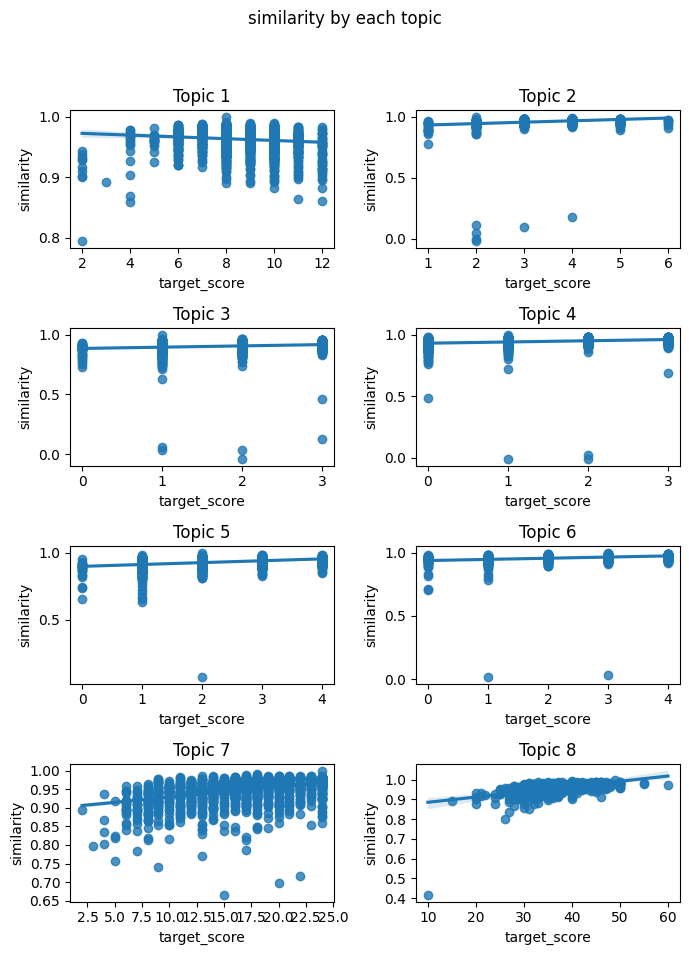

In [14]:
# Plotting document similarity vs target score for each topic

topic_number = 0
fig, ax = plt.subplots(4,2, figsize=(7,10))
for i in range(4):
    for j in range(2):
        topic_number += 1
        sns.regplot(x='target_score', y='similarity', data=training_data[training_data['topic'] == topic_number], ax=ax[i,j])
        ax[i,j].set_title('Topic %i' % topic_number)
ax[3,0].locator_params(nbins=10)
ax[3,1].locator_params(nbins=10)
plt.suptitle('similarity by each topic')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [15]:
# counting various features and applying feature engineering to feed to Neural  Network

training_data['token_count'] = training_data.apply(lambda x: len(x['tokens']), axis=1)

training_data['unique_token_count'] = training_data.apply(lambda x: len(set(x['tokens'])), axis=1)

training_data['nostop_count'] = training_data.apply(lambda x: len([token for token in x['tokens'] if token not in stop_words]), axis=1)

training_data['sent_count'] = training_data.apply(lambda x: len(x['sentences']), axis=1)

training_data['ner_count'] = training_data.apply(lambda x: len(x['nouns']), axis=1)

training_data['comma'] = training_data.apply(lambda x: x['corrected'].count(','), axis=1)

training_data['question'] = training_data.apply(lambda x: x['corrected'].count('?'), axis=1)

training_data['exclamation'] = training_data.apply(lambda x: x['corrected'].count('!'), axis=1)

training_data['quotation'] = training_data.apply(lambda x: x['corrected'].count('"') + x['corrected'].count("'"), axis=1)

training_data['organization'] = training_data.apply(lambda x: x['corrected'].count(r'@ORGANIZATION'), axis=1)

training_data['caps'] = training_data.apply(lambda x: x['corrected'].count(r'@CAPS'), axis=1)

training_data['person'] = training_data.apply(lambda x: x['corrected'].count(r'@PERSON'), axis=1)

training_data['location'] = training_data.apply(lambda x: x['corrected'].count(r'@LOCATION'), axis=1)

training_data['money'] = training_data.apply(lambda x: x['corrected'].count(r'@MONEY'), axis=1)

training_data['time'] = training_data.apply(lambda x: x['corrected'].count(r'@TIME'), axis=1)

training_data['date'] = training_data.apply(lambda x: x['corrected'].count(r'@DATE'), axis=1)

training_data['percent'] = training_data.apply(lambda x: x['corrected'].count(r'@PERCENT'), axis=1)

training_data['noun'] = training_data.apply(lambda x: x['partsofspeech'].count('NOUN'), axis=1)

training_data['adj'] = training_data.apply(lambda x: x['partsofspeech'].count('ADJ'), axis=1)

training_data['pron'] = training_data.apply(lambda x: x['partsofspeech'].count('PRON'), axis=1)

training_data['verb'] = training_data.apply(lambda x: x['partsofspeech'].count('VERB'), axis=1)

training_data['noun'] = training_data.apply(lambda x: x['partsofspeech'].count('NOUN'), axis=1)

training_data['cconj'] = training_data.apply(lambda x: x['partsofspeech'].count('CCONJ'), axis=1)

training_data['adv'] = training_data.apply(lambda x: x['partsofspeech'].count('ADV'), axis=1)

training_data['det'] = training_data.apply(lambda x: x['partsofspeech'].count('DET'), axis=1)

training_data['propn'] = training_data.apply(lambda x: x['partsofspeech'].count('PROPN'), axis=1)

training_data['num'] = training_data.apply(lambda x: x['partsofspeech'].count('NUM'), axis=1)

training_data['part'] = training_data.apply(lambda x: x['partsofspeech'].count('PART'), axis=1)

training_data['intj'] = training_data.apply(lambda x: x['partsofspeech'].count('INTJ'), axis=1)

In [ ]:
# save to file
training_data.to_pickle('training_features.pkl')

In [16]:
list(training_data.columns.values)

['essay_id',
 'topic',
 'essay',
 'rater1_domain1',
 'rater2_domain1',
 'rater3_domain1',
 'target_score',
 'rater1_domain2',
 'rater2_domain2',
 'topic2_target',
 'rater1_trait1',
 'rater1_trait2',
 'rater1_trait3',
 'rater1_trait4',
 'rater1_trait5',
 'rater1_trait6',
 'rater2_trait1',
 'rater2_trait2',
 'rater2_trait3',
 'rater2_trait4',
 'rater2_trait5',
 'rater2_trait6',
 'rater3_trait1',
 'rater3_trait2',
 'rater3_trait3',
 'rater3_trait4',
 'rater3_trait5',
 'rater3_trait6',
 'word_count',
 'matches',
 'corrections',
 'corrected',
 'tokens_sm',
 'lemmatizedtokens_sm',
 'partsofspeech_sm',
 'sentences_sm',
 'nouns_sm',
 'tokens_md',
 'lemmatizedtokens_md',
 'partsofspeech_md',
 'sentences_md',
 'nouns_md',
 'tokens',
 'lemmatizedtokens',
 'partsofspeech',
 'sentences',
 'nouns',
 'similarity',
 'token_count',
 'unique_token_count',
 'nostop_count',
 'sent_count',
 'ner_count',
 'comma',
 'question',
 'exclamation',
 'quotation',
 'organization',
 'caps',
 'person',
 'location',
 

### Topic Modeling with Latent Dirichlet Allocation


In [17]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation #https://towardsdatascience.com/latent-dirichlet-allocation-lda-9d1cd064ffa2
from sklearn.model_selection import train_test_split

In [18]:
import pandas as pd
training_data = pd.read_pickle('training_features.pkl')

In [19]:
#TODO - Replace the topics with the topics in Audio Dataset

topic_dict = {'topic':{1: 'computer',
                       2: 'censorship',
                       3: 'cyclist',
                       4: 'hibiscus',
                       5: 'mood',
                       6: 'dirigibles',
                       7: 'patience',
                       8: 'laughter'}}

training_data.replace(topic_dict, inplace=True)

In [20]:
# creating a list of lemmatized tokens into l_essay column

training_data['l_essay'] = training_data['lemmatizedtokens'].apply(' '.join)

# creating a count vectorizer
count_vectorizer = CountVectorizer(max_df=.2,
                             min_df=3,
                             stop_words=list(STOP_WORDS),
                             max_features=2000)

lemma_matrix = count_vectorizer.fit_transform(training_data.l_essay)
lemma_matrix

<12974x2000 sparse matrix of type '<class 'numpy.int64'>'
	with 546547 stored elements in Compressed Sparse Row format>

In [21]:
# computing most frequent tokens
words = count_vectorizer.get_feature_names_out()

lemma_matrix_df = pd.DataFrame(lemma_matrix.toarray(), columns=words)
print(words, lemma_matrix_df)
word_freq = lemma_matrix_df.sum(axis=0).astype(int)

word_freq.sort_values(ascending=False).head(10)

['1930' '1937' '250' ... 'youth' 'youtube' 'zeppelin']        1930  1937  250  abandon  abhor  ability  able  absolutely  abuse  \
0         0     0    0        0      0        0     0           0      0   
1         0     0    0        0      0        0     1           0      0   
2         0     0    0        0      0        0     0           0      0   
3         0     0    0        0      0        2     0           0      0   
4         0     0    0        0      0        2     1           0      0   
...     ...   ...  ...      ...    ...      ...   ...         ...    ...   
12969     0     0    0        0      0        0     1           0      0   
12970     0     0    0        0      0        0     0           0      0   
12971     0     0    0        0      0        0     0           0      0   
12972     0     0    0        0      0        0     0           0      0   
12973     0     0    0        0      0        0     0           0      0   
       accept  ...  year  yell  y

computer     20394
book         13988
building      7838
library       7632
dirigible     6242
read          6130
child         5770
help          5189
offensive     5117
talk          4978
dtype: int64

In [22]:
import joblib

# Applying LDA on lemma matrix
lda_base_model = LatentDirichletAllocation(n_components=8, n_jobs=-1, learning_method='batch', max_iter=40, perp_tol=0.01, verbose=0, evaluate_every=5)
lda_base_model.fit(lemma_matrix)

joblib.dump(lda_base_model, 'lda_baseline.pkl')

['lda_baseline.pkl']

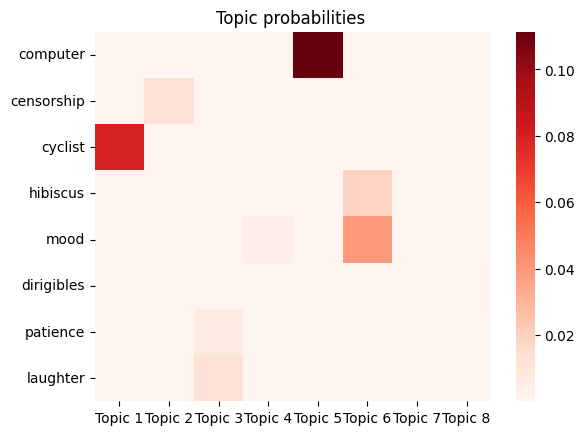

In [23]:
# generating topic probabilities from the LDA
import seaborn as sns
import matplotlib.pyplot as plt

topic_labels = ['Topic {}'.format(i) for i in range(1, 9)]
topics_count = lda_base_model.components_
topics_probability = topics_count / topics_count.sum(axis=1).reshape(-1, 1)
topics = pd.DataFrame(topics_probability.T, index=words, columns=topic_labels)
topics.sample(10)

one_word = list(topic_dict['topic'].values())
sns.heatmap(topics.reindex(one_word), cmap='Reds')
plt.title('Topic probabilities ')
plt.show()

In [24]:
# computing most probable words

probable_words = {}
for topic, words_ in topics.items():
    probable_words[topic] = words_.nlargest(10).index.tolist()
pd.DataFrame(probable_words)


,Topic 1,Topic 2,Topic 3,Topic 4,Topic 5,Topic 6,Topic 7,Topic 8
0,cyclist,book,laugh,old,computer,mood,child,building
1,water,library,patient,town,help,paragraph,kid,dirigible
2,setting,offensive,wait,man,talk,love,movie,obstacle
3,affect,read,person1,water,learn,memoir,book,empire
4,feature,shelf,caps3,hope,spend,test,music,mast
5,road,material,laughter,direction,reason,sang,read,builder
6,hill,remove,caps4,feel,online,hibiscus,library,face
7,hot,right,tell,change,effect,narcissa,magazine,dock
8,desert,person,start,bike,exercise,create,bad,mooring
9,ride,month1,mom,begin,internet,grateful,watch,wind


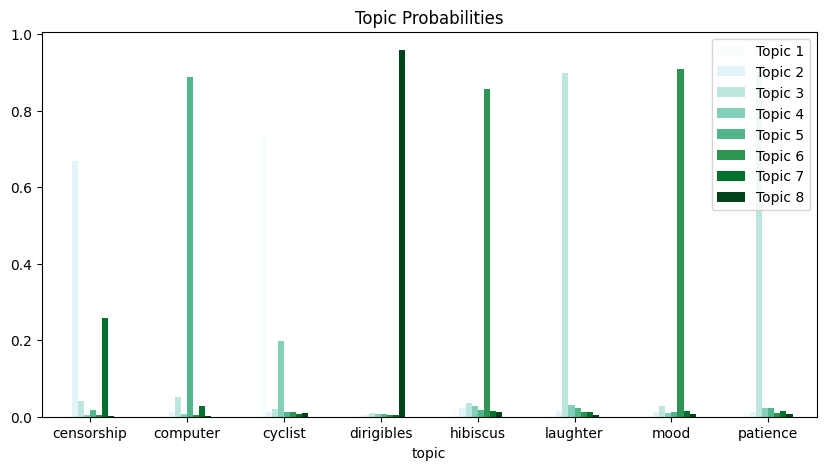

In [25]:
train_predictions = lda_base_model.transform(lemma_matrix)
train_evaluation = pd.DataFrame(train_predictions, columns=topic_labels, index=training_data.topic)
train_evaluation.sample(10)

train_evaluation.groupby(level='topic').mean().plot.bar(title='Topic Probabilities', rot=0, colormap='BuGn', figsize=(10,5));

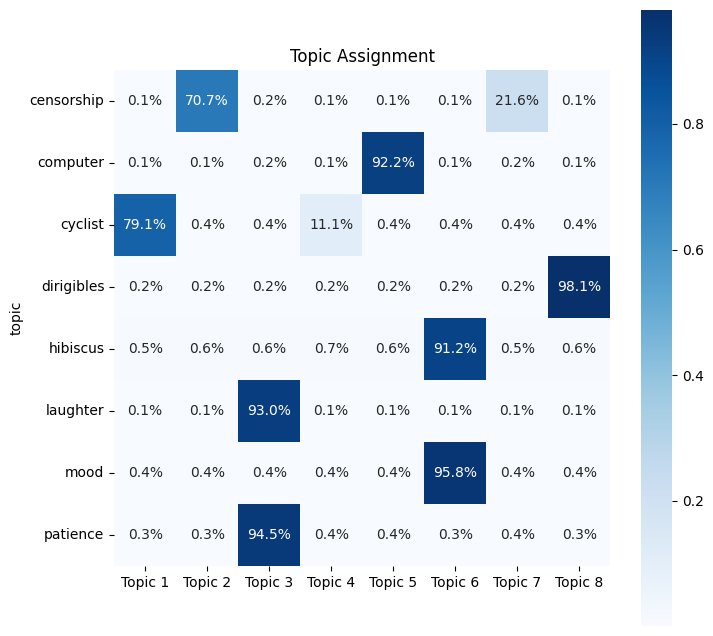

In [26]:
# generating heatmap for topic assignments

df = train_evaluation.groupby(level='topic').agg('median')
fig, ax = plt.subplots(figsize=(8,8))
g = sns.heatmap(df, annot=True, fmt='.1%', annot_kws={"size": 10}, cmap='Blues', square=True)
loc, labels = plt.yticks()
g.set_yticklabels(labels, rotation=0)
g.set_title('Topic Assignment');

In [27]:
df = train_evaluation.idxmax(axis=1).reset_index().groupby('topic', as_index=False).agg(lambda x:x.value_counts().index[0]).rename(columns={0:'assignment'})
df

,topic,assignment
0,censorship,Topic 2
1,computer,Topic 5
2,cyclist,Topic 1
3,dirigibles,Topic 8
4,hibiscus,Topic 6
5,laughter,Topic 3
6,mood,Topic 6
7,patience,Topic 3


### Visualization with PyLDAVis

In [28]:
import pyLDAvis
from pyLDAvis.lda_model import prepare
pyLDAvis.enable_notebook()
plt.rcParams['figure.figsize'] = [8, 5]
plt.rcParams['figure.dpi'] = 100

# fitting base model
prepare(lda_base_model, lemma_matrix, count_vectorizer)

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
2     -0.034704 -0.067374       1        1  22.324508
4     -0.091398  0.027034       2        1  21.312018
1     -0.191807  0.036687       3        1  16.244038
7      0.209121  0.332134       4        1  12.633517
5      0.003794 -0.023115       5        1  12.081971
6     -0.250719  0.025862       6        1   6.817091
0      0.225133 -0.131811       7        1   5.732933
3      0.130580 -0.199418       8        1   2.853924, topic_info=           Term          Freq         Total Category  logprob  loglift
361    computer  20353.000000  20353.000000  Default  30.0000  30.0000
201        book  14010.000000  14010.000000  Default  29.0000  29.0000
228    building   7814.000000   7814.000000  Default  28.0000  28.0000
520   dirigible   6218.000000   6218.000000  Default  27.0000  27.0000
308       child   5831.000000   5831.000000  Default  26.0000  26.0000
...         ...           ...           ...      ...      ...      ...
1022      leave    211.269755   2426.313650   Topic8  -4.7520   1.1155
389    continue    143.270136    479.225065   Topic8  -5.1404   2.3490
1318      place    172.785279   3377.829783   Topic8  -4.9530   0.5835
707     finally    155.696633   1618.166980   Topic8  -5.0572   1.2153
601         end    156.285386   2304.432331   Topic8  -5.0534   0.8656

[504 rows x 6 columns], token_table=      Topic      Freq     Term
term                          
3         4  0.028553  abandon
3         7  0.277370  abandon
3         8  0.689345  abandon
4         3  0.988640    abhor
6         1  0.122645     able
...     ...       ...      ...
1996      2  0.043370    young
1996      3  0.064721    young
1996      5  0.050709    young
1996      6  0.694582    young
1996      8  0.037365    young

[1315 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[3, 5, 2, 8, 6, 7, 1, 4])

In [29]:
hibiscus = training_data[training_data.topic == 'hibiscus']

# Split essays into training and test sets
train_essays, test_essays = train_test_split(hibiscus, stratify=hibiscus.target_score, test_size=0.2, random_state=42)
print(train_essays, test_essays)

count_vectorizer = CountVectorizer(max_df=.2, min_df=3, stop_words=list(STOP_WORDS), max_features=399)

# Train and test lemma matrices
train_lm = count_vectorizer.fit_transform(train_essays.l_essay)
test_lm = count_vectorizer.fit_transform(test_essays.l_essay)

lda_score = LatentDirichletAllocation(n_components=4, n_jobs=-1, learning_method='batch', evaluate_every=5, verbose=0, max_iter=500)
lda_score.fit(train_lm)

# save training model
joblib.dump(lda_score, 'lda_score.pkl')

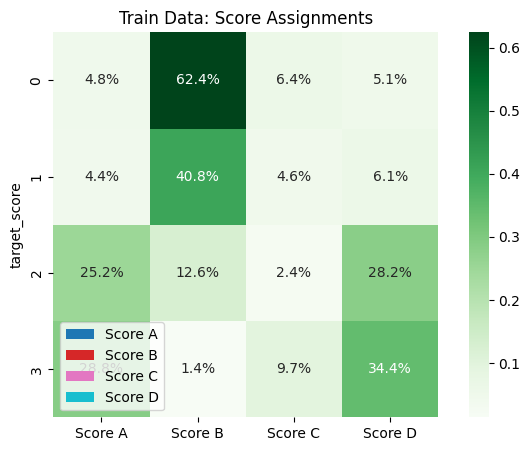

In [30]:
# Analyzing and Visualizing LDA Topic Model Results
topic_labels = ['Score A', 'Score B', 'Score C', 'Score D']

train_predictions = lda_score.transform(train_lm)
train_evaluation = pd.DataFrame(train_predictions, columns=topic_labels, index=train_essays.target_score)
train_evaluation.sample(5)

train_evaluation.groupby(level='target_score').mean().plot.bar(title='Avg. Topic Probabilities', rot=0, colormap='tab10', figsize=(8,5));

df = train_evaluation.groupby(level='target_score').agg('median')
sns.heatmap(df, annot=True, fmt='.1%', cmap='Greens', square=True)
plt.title('Train Data: Score Assignments');

In [31]:
df = train_evaluation.idxmax(axis=1).reset_index().groupby('target_score', as_index=False).agg(lambda x:x.value_counts().index[0]).rename(columns={0:'assignment'})
df

,target_score,assignment
0,0,Score B
1,1,Score B
2,2,Score A
3,3,Score D


In [32]:
test_prediction = lda_score.transform(test_lm)
test_evaluation = pd.DataFrame(test_prediction, columns=topic_labels, index=test_essays.target_score)
test_evaluation.head()

,Score A,Score B,Score C,Score D
target_score,,,,
1,0.449024,0.320598,0.205526,0.024853
2,0.315985,0.448065,0.219236,0.016714
1,0.036606,0.324507,0.038118,0.600769
1,0.195110,0.558063,0.225014,0.021812
0,0.083633,0.084279,0.090344,0.741744


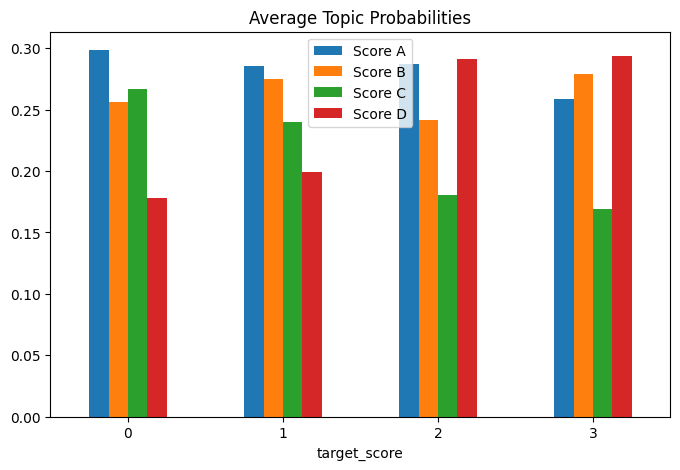

In [33]:
test_evaluation.groupby(level='target_score').mean().plot.bar(title='Average Topic Probabilities', rot=0);


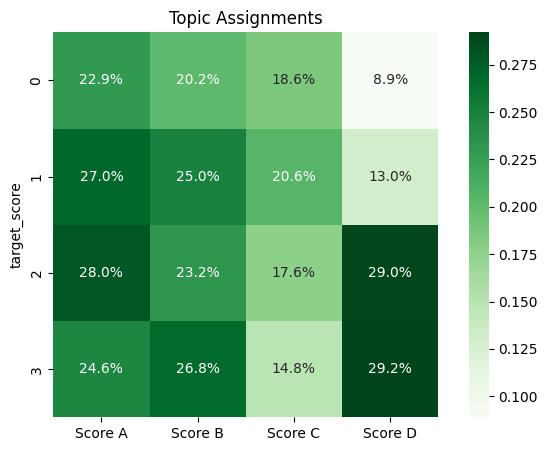

In [34]:
df = test_evaluation.groupby(level='target_score').agg('median')
sns.heatmap(df, annot=True, fmt='.1%', cmap='Greens', square=True)
plt.title('Topic Assignments')
plt.show()

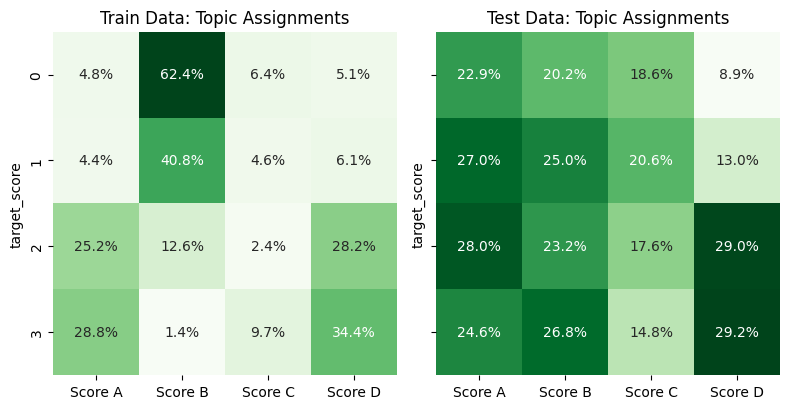

In [37]:
fig, axes = plt.subplots(ncols=2, figsize=(8,6), sharey=True)
source = ['Train', 'Test']
for i, df in enumerate([train_evaluation, test_evaluation]):
    df = df.groupby(level='target_score').agg('median')
    sns.heatmap(df, annot=True, fmt='.1%', cmap='Greens', square=True, ax=axes[i], cbar=False)
    axes[i].set_title('{} Data: Topic Assignments'.format(source[i]))
plt.tight_layout()
plt.show()

## Scoring Leveraging Neural Networks Models

In [38]:
# Import necessary modules
from sklearn.model_selection import cross_val_score, KFold
from nltk.corpus import stopwords
import language_tool_python
import spacy

from sklearn.model_selection import train_test_split, KFold
from skll.metrics import kappa
from scipy.sparse import csr_matrix
import scikeras
import tensorflow
import nltk

In [39]:
import language_tool_python

def correct_language(data):
  tool = language_tool_python.LanguageTool('en-US')
  data['matches'] = data['essay'].apply(lambda txt: tool.check(txt))
  data['corrections'] = data.apply(lambda l: len(l['matches']), axis=1)
  data['corrected'] = data.apply(lambda l:  tool.correct(l['essay']), axis=1)

  return data

In [ ]:
# Prepare combined dataset from validation and test dataset

validation_data  = pd.read_csv('validation_data.tsv', sep='\t', encoding = "ISO-8859-1").rename(columns={'essay_set': 'topic'})

testing_data  = pd.read_csv('testing_data.tsv', sep='\t', encoding = "ISO-8859-1").rename(columns={'essay_set': 'topic'})

combined_data = pd.concat([validation_data, testing_data], sort=False)

# applying corrections
combined_data = correct_language(combined_data)

In [ ]:
# Combining training dataset
combined_data = pd.concat([combined_data, training_data], sort=False)

combined_data.to_pickle('combined_dataset.pkl')

In [40]:
import pandas as pd
combined_data = pd.read_pickle('combined_dataset.pkl')


#### Generate word embeddings with Word2Vec
###### Generating word embedding with 2-layer NN word2vec to obtain vector representation of words

In [57]:
import string
# Clean training_set essays before feeding them to the Word2Vec model.
punctuations = string.punctuation

print(stop_words, punctuations)

{'hereby', 'seeming', '’m', '’d', 'wherever', 'up', 'down', 'by', 'yourselves', 'never', 'must', 'hereupon', 'enough', 'if', 'under', 'your', 'has', 'latter', 'any', 'whoever', '|', 'back', 'although', '-', 'also', 'whatever', ')', '*', 'a', 'many', 'to', 'upon', '(', 'eleven', 'between', "'ve", 'always', 'per', 'it', 'do', 'else', 'used', 'across', 'seems', 'too', 'this', 'ours', 'first', 'no', 'those', 'might', 'only', 'became', 'who', 'fifteen', 'mine', 'they', 'much', 'why', 'was', 'whereupon', 'out', '\\', 'last', 'during', 'he', 'alone', 'against', 'thereupon', 'with', 'say', 'another', 'next', '=', 'in', 'one', 'nor', 'thus', 'anyway', 'whether', '{', 'show', "n't", 'about', '[', 'themselves', 'therein', 'after', 'or', 'noone', '’s', 'for', 'becoming', 'nothing', 'see', 'being', 'than', '‘m', 'n’t', 'everything', 'same', 'nevertheless', 'own', 'myself', 'most', '}', 'but', 'twelve', 'least', 'rather', '‘d', 'were', 'throughout', 'again', 'just', ':', 'further', 'would', '+', 'ex

In [42]:
# Removing pronouns, stopwords and punctuations from the essay
def clean_text(essays, logging=False):
    texts = []
    counter = 1
    for essay in essays.corrected:
        if counter % 2000 == 0 and logging:
            print("Processed %d out of %d documents." % (counter, len(essays)))
        counter += 1
        essay = nlp(essay, disable=['parser', 'ner'])
        tokens = [tok.lemma_.lower().strip() for tok in essay if tok.lemma_ != '-PRON-']
        tokens = [tok for tok in tokens if tok not in stop_words and tok not in punctuations]
        tokens = ' '.join(tokens)
        texts.append(tokens)
    return pd.Series(texts)

In [43]:
# Cleanup text and make sure it retains original shape

training_cleaned_dataset = clean_text(training_data, logging=True)
print(training_cleaned_dataset.shape)

Processed 2000 out of 12974 documents.
Processed 4000 out of 12974 documents.
Processed 6000 out of 12974 documents.
Processed 8000 out of 12974 documents.
Processed 10000 out of 12974 documents.
Processed 12000 out of 12974 documents.
(12974,)


In [44]:
# Reference: https://github.com/Turanga1/Automated-Essay-Scoring/blob/master/2_Automatic_Scoring_with_Neural_Networks.ipynb

# preprocessing text from the essays using Word2Vec
import re
def clean_text_word2vec(essays, logging=False):
    sentences = []
    counter = 1
    for essay in essays:
        if counter % 2000 == 0 and logging:
            print("Processing %d out of %d documents" % (counter, len(essays)))
        # Disable tagger so that lemma_ of personal pronouns (I, me, etc) don't getted marked as "-PRON-"
        essay = nlp(essay, disable=['tagger'])
        # Grab lemmatized form of words and make lowercase
        essay = " ".join([tok.lemma_.lower() for tok in essay])
        # Split into sentences based on punctuation
        essay = re.split("[\.?!;] ", essay)
        # Remove commas, periods, and other punctuation (mostly commas)
        essay = [re.sub("[\.,;:!?]", "", sent) for sent in essay]
        # Split into words
        essay = [sent.split() for sent in essay]
        sentences += essay
        counter += 1
    return sentences

cleaned_word2vec = clean_text_word2vec(combined_data['corrected'], logging=True)
print('Cleaned up training data size (i.e. number of sentences): ', len(cleaned_word2vec))

Processing 2000 out of 21445 documents
Processing 4000 out of 21445 documents
Processing 6000 out of 21445 documents
Processing 8000 out of 21445 documents
Processing 10000 out of 21445 documents
Processing 12000 out of 21445 documents
Processing 14000 out of 21445 documents
Processing 16000 out of 21445 documents
Processing 18000 out of 21445 documents
Processing 20000 out of 21445 documents
Cleaned up training data size (i.e. number of sentences):  291659


In [45]:
# tuning model paramerters

from gensim.models.word2vec import Word2Vec

text_dimensionality = 400

word2vec_model = Word2Vec(cleaned_word2vec,
                         vector_size = text_dimensionality,
                         window = 3,
                         min_count = 5,
                         workers = 4,
                         sg = 1)

print("%d unique words represented by %d dimensional vectors" % (len(word2vec_model.wv.index_to_key), text_dimensionality))
word2vec_model.save('wordvec_model')

11055 unique words represented by 400 dimensional vectors


In [46]:
from gensim.models.word2vec import Word2Vec
text_dimensionality = 400
word2vec_model = Word2Vec.load('wordvec_model')

In [47]:
# Creating averaged word vectors for a cleaned text.
import numpy as np
def create_average_vec(essay):
    average = np.zeros((text_dimensionality,), dtype='float32')
    num_words = 0.
    for word in essay.split():
        if word in word2vec_model.wv.index_to_key:
            average = np.add(average, word2vec_model.wv[word])
            num_words += 1.
    if num_words != 0.:
        average = np.divide(average, num_words)
    return average

cleaned_vector = np.zeros((training_data.shape[0], text_dimensionality), dtype="float32")
for i in range(len(training_cleaned_dataset)):
    cleaned_vector[i] = create_average_vec(training_cleaned_dataset[i])

print("Word Cleaned vectors - shape:", cleaned_vector.shape)

Word Cleaned vectors - shape: (12974, 400)


In [48]:
from sklearn.preprocessing import MinMaxScaler,StandardScaler
# reading generated features from features pickle file
additional_features = pd.read_pickle('training_features.pkl')

# Selecting features from Gini feature importances
feature_list = [
                'word_count',
                'corrections',
                'similarity',
                'token_count',
                'unique_token_count',
                'nostop_count',
                'sent_count',
                'ner_count',
                'comma',
                'question',
                'exclamation',
                'quotation',
                'organization',
                'caps',
                'person',
                'location',
                'money',
                'time',
                'date',
                'percent',
                'noun',
                'adj',
                'pron',
                'verb',
                'cconj',
                'adv',
                'det',
                'propn',
                'num',
                'part',
                'intj'
                ]

additional_features = additional_features[feature_list]

standardscaler = StandardScaler()
additional_features = standardscaler.fit_transform(additional_features)
additional_features.shape

# Combine topic number, target score, additional features and cleaned word vectors
entire_data = pd.concat([training_data[['topic','target_score']], pd.DataFrame(additional_features), pd.DataFrame(cleaned_vector)], axis=1)
entire_data.shape

(12974, 433)

### Approach 1: Passing Each Topic Individually through Model


In [58]:
from keras.models import Sequential, Model
from keras.layers import Dense, Dropout, Input, LSTM, Bidirectional, Flatten
from keras.layers import Conv1D, MaxPooling1D, GlobalMaxPooling1D
from keras.optimizers import Adam


# Building the neural network model
output_dimension = 1
input_dimension = entire_data.shape[1]-2
dropout = 0.2

# Initializing the model
model = None
model = Sequential()

# Densely Connected Neural Network
model.add(Dense(14,
                activation='relu',
                kernel_initializer='he_normal',
                input_dim = input_dimension))
model.add(Dropout(dropout))

# model.add(Dense(8, activation='relu', kernel_initializer='he_normal'))
# model.add(Dropout(dropout))

model.add(Dense(output_dimension))
model.summary()

# Compiling the neural network model with adam optimizer
adam = Adam(learning_rate=0.0001, beta_1=0.9, beta_2=0.999, epsilon=1e-5) # 1e-7

model.compile(optimizer=adam, loss='mean_squared_error', metrics=['mse','mae'])

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                      │ (None, 14)                  │           6,048 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 14)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │              15 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 6,063 (23.68 KB)

 Trainable params: 6,063 (23.68 KB)

 Non-trainable params: 0 (0.00 B)

In [50]:
# Reference: https://github.com/Turanga1/Automated-Essay-Scoring/blob/master/bhkappa.py
import numpy as np
# kappa scoring function
def mean_quadratic_weighted_kappa(kappas, weights=None):

    kappas = np.array(kappas, dtype=float)
    if weights is None:
        weights = np.ones(np.shape(kappas))
    else:
        weights = weights / np.mean(weights)

    # ensure that kappas are in the range [-.999, .999]
    kappas = np.array([min(x, .999) for x in kappas])
    kappas = np.array([max(x, -.999) for x in kappas])

    z = 0.5 * np.log((1 + kappas) / (1 - kappas)) * weights
    z = np.mean(z)
    return (np.exp(2 * z) - 1) / (np.exp(2 * z) + 1)

In [59]:
# Initialize lists to store kappa scores and weights
kappa_list = []
weights = []
epochs = 100

# Iterate over each topic
for topic in entire_data.topic.unique():
    # Split data for the current topic
    X = entire_data[entire_data.topic == topic].drop(['topic', 'target_score'], axis=1)
    y = entire_data[entire_data.topic == topic].target_score.to_frame()
    #X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, train_size=0.8, random_state=26)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=26)
    print(X_train.shape)
    print(y_train.shape)
    print(X_train.isnull().values.any())
    print(y_train.isnull().values.any())
    # Fit the model to the training data
    estimator = model.fit(X_train, y_train, epochs=epochs, batch_size=16)

    # Check if model training failed
    if estimator is None:
        print("Model training failed for topic:", topic)
        continue

    # Make predictions on the test data
    y_pred = pd.DataFrame(model.predict(X_test).reshape(-1))
    print(y_pred)
    # Compute kappa score for the current topic
    kappa_list.append(kappa(y_test.values, y_pred.round(0).astype(int).values, weights='quadratic'))

    # Calculate weight for the current topic
    weights.append(y_test.shape[0] / entire_data.shape[0])

# Calculate weighted average kappa
qwk = mean_quadratic_weighted_kappa(kappa_list, weights=1)
print('Combined Kappa score: {:.2f}%'.format(qwk * 100))


(1426, 431)
(1426, 1)
False
False
             0
0     8.007124
1     8.000915
2     7.181155
3    11.116107
4     8.071589
..         ...
352   5.963034
353   8.092309
354   4.569280
355   7.617715
356   5.391023
[357 rows x 1 columns]
(1440, 431)
(1440, 1)
False
False


            0
0    3.328198
1    3.835823
2    3.627716
3    2.810888
4    3.580529
..        ...
355  3.353885
356  2.895014
357  3.376235
358  3.851960
359  3.642345
[360 rows x 1 columns]
(1380, 431)
(1380, 1)
False
False


            0
0    1.714563
1    2.321260
2    1.849601
3    2.211967
4    2.383782
..        ...
341  1.872671
342  1.804470
343  0.939464
344  0.870135
345  1.169290
[346 rows x 1 columns]
(1414, 431)
(1414, 1)
False
False


            0
0    1.320638
1    1.626680
2    2.556448
3    0.479529
4    1.191771
..        ...
349  1.194738
350  2.473256
351  0.433831
352  2.540145
353  1.033666
[354 rows x 1 columns]
(1444, 431)
(1444, 1)
False
False


            0
0    2.625376
1    0.956290
2    2.660750
3    3.662944
4    1.065909
..        ...
356  1.973277
357  2.917973
358  2.019792
359  1.117328
360  3.016788
[361 rows x 1 columns]
(1440, 431)
(1440, 1)
False
False


            0
0    2.792231
1    3.702372
2    2.869435
3    3.441097
4    1.244507
..        ...
355  3.280820
356  3.129480
357  1.679453
358  1.664287
359  2.304914
[360 rows x 1 columns]
(1255, 431)
(1255, 1)
False
False


             0
0    19.707102
1    21.102335
2    16.451759
3    15.962263
4    15.372919
..         ...
309  13.117773
310  21.328243
311  15.369377
312  17.503778
313  10.583839
[314 rows x 1 columns]
(578, 431)
(578, 1)
False
False


             0
0    34.641819
1    42.304909
2    30.227654
3    36.673534
4    40.705345
..         ...
140  42.607861
141  34.497448
142  30.482904
143  34.007889
144  33.793240
[145 rows x 1 columns]
Combined Kappa score: 73.63%


In [ ]:
# Computting each topic individually
kappa_list = []
weights = []
epochs = 100

for topic in entire_data.topic.unique():
    # split data
    X = entire_data[entire_data.topic == topic].drop(['topic', 'target_score'], axis=1)
    y = entire_data[entire_data.topic == topic].target_score.to_frame()
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=26)
    print(X_train.shape)
    print(y_train.shape)
    estimator = model.fit(X_train, y_train,epochs=epochs, batch_size=16)
    if estimator is None:
        print("Model training failed for topic:", topic)
        continue

    y_pred = pd.DataFrame(model.predict(X_test).reshape(-1))
    print(y_pred)
    kappa_list.append(kappa(y_test.values, y_pred.round(0).astype(int).values, weights='quadratic'))

    weights.append(y_test.shape[0]/entire_data.shape[0])

# get weighted average kappa
qwk = mean_quadratic_weighted_kappa(kappa_list, weights=1) # weights)
print('Combined Kappa score: {:.2f}%'.format(qwk * 100))

(1426, 431)
(1426, 1)


(1440, 431)
(1440, 1)
(1380, 431)
(1380, 1)


(1414, 431)
(1414, 1)


(1444, 431)
(1444, 1)


(1440, 431)
(1440, 1)


(1255, 431)
(1255, 1)
(578, 431)
(578, 1)


Combined Kappa score: 68.33%


In [60]:
# Cross-validation

kappa_dict = {}

for topic in entire_data.topic.unique():

    model = None
    # create model
    model = Sequential()
    model.add(Dense(14, input_dim=input_dimension, kernel_initializer='he_normal', activation='relu'))
    model.add(Dropout(dropout))
    model.add(Dense(1))
    # Compile model
    model.compile(loss='mean_squared_error', optimizer='adam')

    X = entire_data[entire_data.topic == topic].drop(['topic', 'target_score'], axis=1)
    y = entire_data[entire_data.topic == topic].target_score.to_frame()
    # split data
    kf = KFold(n_splits=5, shuffle=True, random_state=26)
    kappa_list = []
    for train, test in kf.split(X):
        X_train, X_test = X.iloc[train], X.iloc[test]
        y_train, y_test = y.iloc[train], y.iloc[test]
        model.fit(X_train, y_train, epochs=100, batch_size=15, verbose=0)
        y_pred = pd.DataFrame(model.predict(X_test).reshape(-1))
        print(y_pred)
        kappa_list.append(kappa(y_pred.round(0).astype(int).values,
                        y.iloc[test].values,
                        weights='quadratic'))
    print("Kappa for topic", topic, ": {:.3f}%".format(np.mean(kappa_list)))
    kappa_dict[topic] = np.mean(kappa_list)

mqwk = mean_quadratic_weighted_kappa(list(kappa_dict.values()), weights=1) # weights)
print('Combined Kappa score: {:.4f}%'.format(mqwk))

            0
0    7.281167
1    8.853629
2    6.452907
3    7.878907
4    3.078610
..        ...
352  4.450323
353  8.605381
354  8.893903
355  4.807151
356  2.460889
[357 rows x 1 columns]


            0
0    8.166268
1    9.325870
2    8.089589
3    3.233262
4    4.522377
..        ...
352  8.480063
353  8.553488
354  8.285534
355  9.630404
356  6.595277
[357 rows x 1 columns]


             0
0     8.275670
1     6.348641
2     8.311662
3     4.823900
4    10.109048
..         ...
352   8.612903
353   8.774371
354   8.825950
355   9.001184
356   7.936116
[357 rows x 1 columns]


             0
0     6.586577
1    10.311073
2     8.813232
3     3.802995
4     9.756408
..         ...
351  10.534357
352  10.437872
353   9.507826
354   9.600405
355   7.012602
[356 rows x 1 columns]


             0
0     8.288268
1     9.155701
2    10.504680
3     9.800578
4     9.508703
..         ...
351   8.737784
352   7.985953
353   8.972927
354   9.404770
355   8.162914
[356 rows x 1 columns]
Kappa for topic computer : 0.833%


...

             0
0    40.635532
1    12.577960
2    36.783112
3    34.930206
4    41.391724
..         ...
140  35.546886
141  43.071125
142  39.244411
143  38.668579
144  33.528679
[145 rows x 1 columns]


             0
0    25.707376
1    34.779259
2    35.463703
3    31.585098
4    39.274780
..         ...
140  33.071568
141  35.963547
142  32.444077
143  36.739159
144  26.862633
[145 rows x 1 columns]


             0
0    27.897137
1    36.040543
2    32.117031
3    32.925713
4    41.568771
..         ...
140  44.676376
141  42.788448
142  37.371323
143  38.936794
144  41.769051
[145 rows x 1 columns]


             0
0    29.783110
1    39.673130
2    38.129757
3    40.551487
4    34.236298
..         ...
139  41.553791
140  32.857727
141  12.906404
142  38.447498
143  39.136684
[144 rows x 1 columns]


             0
0    27.804771
1    41.920685
2    29.990864
3    42.001106
4    33.289253
..         ...
139  34.930702
140  41.723080
141  36.325867
142  35.911560
143  30.701031
[144 rows x 1 columns]
Kappa for topic laughter : 0.698%
Combined Kappa score: 0.7756%


#### Approach 2: Combining all topics


In [61]:
scores = entire_data[['topic', 'target_score']].reset_index()
scores.head()

,index,topic,target_score
0,0,computer,8
1,1,computer,9
2,2,computer,7
3,3,computer,10
4,4,computer,8


In [63]:
scores = entire_data[['topic', 'target_score']].reset_index()

# Rescale target_score (essay grades) in range 0 - 60:
scaler = MinMaxScaler((0,10))

# Rescale and assign target variable y
scaled = []
for topic in entire_data.topic.unique():
    topic_scores = scores[scores['topic'] == topic]['target_score'].to_frame()
    s = (scaler.fit_transform(topic_scores).reshape(-1))
    scaled = np.append(scaled, s)

scores['scaled'] = scaled

y = scores['scaled'].to_frame()

# Features
X = entire_data.drop(['topic', 'target_score'], axis=1)
print(X, y)

            0         1         2         3         4         5         6    \
0      0.655204  0.710760  0.561178  0.724571  0.888389  0.665301  0.233644   
1      1.115669  1.408370  0.549357  1.029625  1.242808  1.199544  0.673255   
2      0.319804  0.411785  0.410762  0.289494  0.633207  0.301044  0.057799   
3      1.712568  1.906663 -0.490682  1.624730  2.065061  2.170895  1.376634   
4      1.377168  0.810419  0.570563  1.334679  1.285339  1.187402  1.464556   
...         ...       ...       ...       ...       ...       ...       ...   
12969  3.537374  0.910077  0.441830  3.560071  3.227557  3.117962  1.552478   
12970  1.837633  3.401541  0.430757  1.969791  1.568874  1.758071  2.607546   
12971  3.378201  0.411785  0.911884  3.510062  3.723744  3.518645  2.695468   
12972  1.928589 -0.385484  0.475337  2.089812  2.008354  1.988767  2.343779   
12973  1.388537 -0.784118  0.516825  1.394689  1.653935  1.685219  1.376634   
            7         8         9    ...       390  

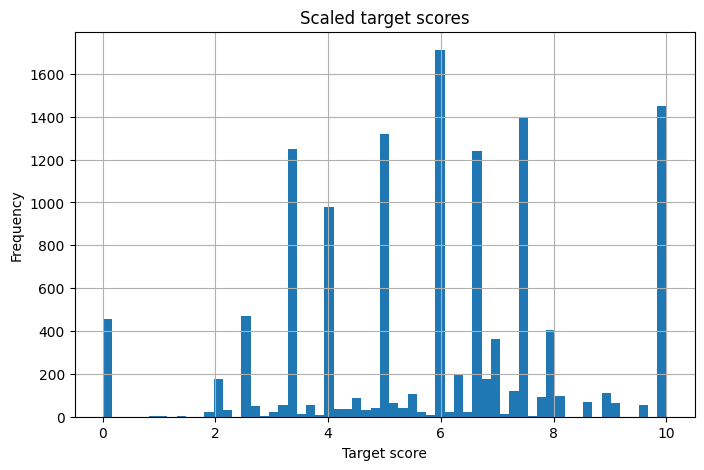

In [64]:
# Plotting Score histogram
y.hist(bins=61)
plt.title('Scaled target scores')
plt.xlabel('Target score')
plt.ylabel('Frequency')
plt.show()

In [81]:
from sklearn.model_selection import train_test_split

# Data to be split
X_train, X_test, y_train, y_test, scores_train, scores_test = \
        train_test_split(
                X,
                y,
                scores,
                test_size=0.2,
                random_state=26
                )

# Expanding dimensions of training data
print('X_train size: {}'.format(X_train.shape))
print('X_test size: {}'.format(X_test.shape))
#X_train = np.expand_dims(X_train, axis=2)
#X_test = np.expand_dims(X_test, axis=2)
#print('X_train size: {}'.format(X_train.shape))
#print('X_test size: {}'.format(X_test.shape))
print('y_train size: {}'.format(y_train.shape))
print('y_test size: {}'.format(y_test.shape))
print('scores_train size: {}'.format(scores_train.shape))
print('scores_test size: {}'.format(scores_test.shape))

output_dimension = y.shape[1]
input_dimension = X.shape[1]
dropout = 0.2


# Model Architechture Using LSTM
model = Sequential()
inputs = Input(shape=(input_dimension,1))
x = Bidirectional(LSTM(64, return_sequences=True),
                          merge_mode='concat')(inputs)
x = Dropout(dropout)(x)
x = Flatten()(x)
outputs = Dense(output_dimension)(x) #, activation='softmax'

model = Model(inputs=inputs, outputs=outputs, name='LSTM')

model.summary()

X_train size: (10379, 431)
X_test size: (2595, 431)
y_train size: (10379, 1)
y_test size: (2595, 1)
scores_train size: (10379, 4)
scores_test size: (2595, 4)


Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_15 (InputLayer)          │ (None, 431, 1)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional_4 (Bidirectional)      │ (None, 431, 128)            │          33,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_15 (Dropout)                 │ (None, 431, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_4 (Flatten)                  │ (None, 55168)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_26 (Dense)                     │ (None, 1)                   │          55,169 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 88,961 (347.50 KB)

 Trainable params: 88,961 (347.50 KB)

 Non-trainable params: 0 (0.00 B)

In [82]:
# Compile the model with Adam optimizer
from tensorflow.keras.callbacks import EarlyStopping
adam = Adam(learning_rate=0.0001, beta_1=0.9, beta_2=0.999, epsilon=1e-5)
model.compile(optimizer=adam, loss='mean_squared_error', metrics=['mse','mae'])
early_stopping = EarlyStopping(monitor='val_loss', patience=5)

epochs = 10
estimator = model.fit(X_train, y_train, epochs=epochs, batch_size=16)
model.save('LSTM_model.h5')

#### Results

In [83]:
print('X_test size: {}'.format(X_test.shape))
print(model.predict(X_test))
y_pred = pd.DataFrame(model.predict(X_test).reshape(-1))
print(y_pred)
# Merge results
results = scores_test.reset_index(drop=True)\
                    .join(y_pred)\
                    .rename(columns={0:'y_pred'})\
                    .sort_values(by='topic')\
                    .reset_index(drop=True)
results.head()

X_test size: (2595, 431)
[[8.017062 ]
 [5.8503   ]
 [6.202329 ]
 ...
 [5.1883273]
 [6.7658453]
 [7.477284 ]]
             0
0     8.017062
1     5.850300
2     6.202329
3     4.218484
4     6.568424
...        ...
2590  6.188037
2591  6.249716
2592  5.188327
2593  6.765845
2594  7.477284
[2595 rows x 1 columns]


,index,topic,target_score,scaled,y_pred
0,3250,censorship,3,4.0,5.116545
1,2799,censorship,4,6.0,5.164461
2,2439,censorship,3,4.0,3.958499
3,2308,censorship,3,4.0,3.941695
4,1987,censorship,2,2.0,4.055764


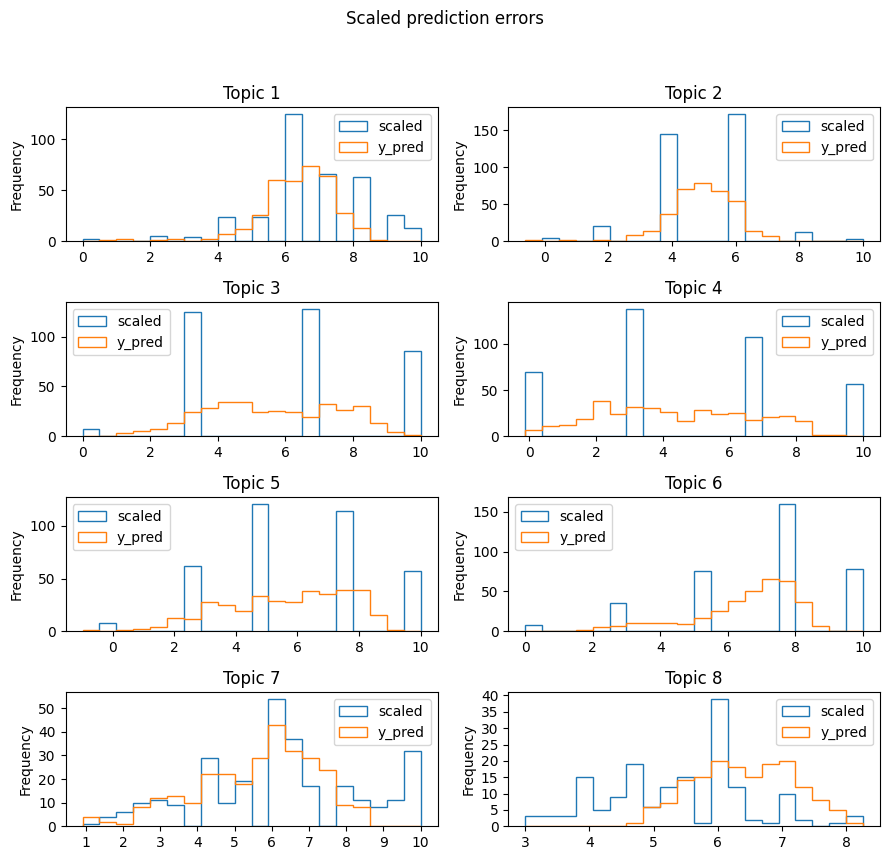

In [86]:
## Histogram of Scaled Prediction Errors for Each Topic
topic_names = ['computer', 'censorship', 'cyclist', 'hibiscus', 'mood', 'dirigibles', 'patience', 'laughter']
topic_number = 0
fig, ax = plt.subplots(4,2, figsize=(9,9), sharey=False)
for i in range(4):
    for j in range(2):
        results[results['topic'] == topic_names[topic_number]][['scaled', 'y_pred']].plot.hist(histtype='step', bins=20, ax=ax[i, j], rot=0)
        topic_number += 1
        ax[i,j].set_title('Topic %i' % topic_number)
ax[3,0].locator_params(nbins=10)
ax[3,1].locator_params(nbins=10)
plt.suptitle('Scaled prediction errors')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

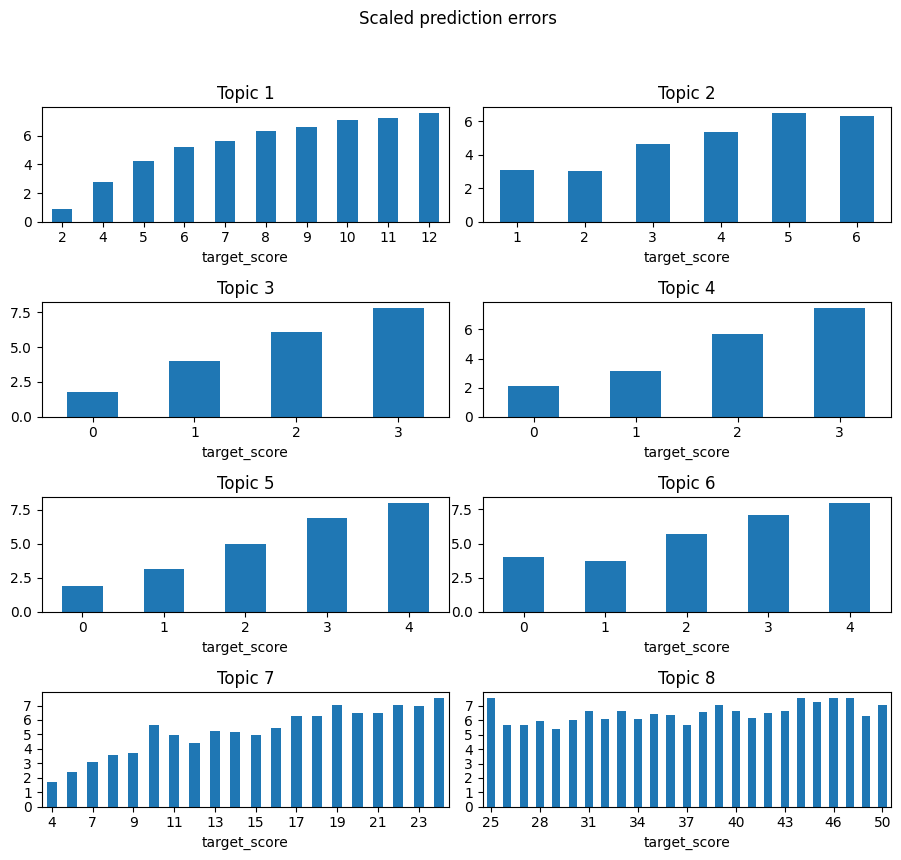

In [89]:
## Median Difference in Scaled Prediction Errors for Each Topic and Target Score

topic_number = 0
fig, ax = plt.subplots(4,2, figsize=(9,9), sharey=False)
for i in range(4):
    for j in range(2):
        results[results['topic'] == topic_names[topic_number]].groupby('target_score')['y_pred'].median().plot.bar(ax=ax[i, j], rot=0)
        topic_number += 1
        ax[i,j].set_title('Topic %i' % topic_number)
ax[3,0].locator_params(nbins=10)
ax[3,1].locator_params(nbins=10)
plt.suptitle('Scaled prediction errors')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [93]:
## Transform Scaled Prediction and True Values Back to Original Range by Topic Number

score_df = results.groupby('topic')['target_score'].agg(['min', 'max'])
score_ranges = list(zip(score_df['min'], score_df['max']))

y_p_df = pd.Series() # y_predicted dataframe
y_t_df = pd.Series() #y_true dataframe

for topic in range(0,8):
    scaler = MinMaxScaler(score_ranges[topic])
    scaled_pred = results[results.topic == topic_names[topic]]['y_pred'].to_frame()
    y_pred_shrunk = scaler.fit_transform(scaled_pred).round(0).astype('int')
    scaled_true = results[results.topic == topic_names[topic]]['scaled'].to_frame()
    y_true_shrunk = scaler.fit_transform(scaled_true).round(0).astype('int')
    #y_p_df = y_p_df.append(pd.Series(np.squeeze(np.asarray(y_pred_shrunk))), ignore_index=True)
    #y_t_df = y_t_df.append(pd.Series(np.squeeze(np.asarray(y_true_shrunk))), ignore_index=True)
    y_p_df = pd.concat([y_p_df, pd.Series(np.squeeze(np.asarray(y_pred_shrunk)))], ignore_index=True)
    y_t_df = pd.concat([y_t_df, pd.Series(np.squeeze(np.asarray(y_true_shrunk)))], ignore_index=True)



# Append to results df
results['pred'] = y_p_df
results['y_true'] = y_t_df
results.head()

,index,topic,target_score,scaled,y_pred,pred,y_true
0,3250,censorship,3,4.0,5.116545,4,4
1,2799,censorship,4,6.0,5.164461,5,6
2,2439,censorship,3,4.0,3.958499,5,4
3,2308,censorship,3,4.0,3.941695,4,5
4,1987,censorship,2,2.0,4.055764,3,3


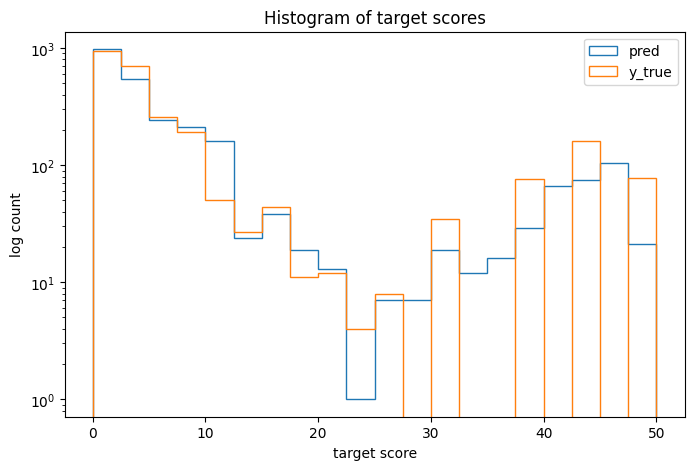

In [94]:
# histogram on Scores

results[['pred', 'y_true']].plot.hist(histtype='step', bins=20, logy=True)
plt.title('Histogram of target scores')
plt.xlabel('target score')
plt.ylabel('log count')
plt.savefig('image8.png', dpi=300)
plt.show()

#### kappa Scores

In [95]:
k = kappa(results.pred, results.target_score, weights='quadratic')
print('Combined essay kappa score: {:.4f}'.format(k))

Combined essay kappa score: 0.4725


In [97]:
## Calculate Weighted Quadratic Kappa Score by Topic

qwk = []
# weights = []
for topic in range(0,8):
    qwk.append(
            kappa(results[results.topic == topic_names[topic]]['target_score'],
                  results[results.topic == topic_names[topic]]['pred'],
                    weights='quadratic'))
#     weights.append(len(results[results.topic==topic])/X_test.shape[0])
mqwk = mean_quadratic_weighted_kappa(qwk, weights=1)
print('Weighted by topic Kappa score: {:.2f}%'.format(mqwk * 100))
qwk

Weighted by topic Kappa score: 5.64%


[-0.022391718877690092,
 -0.03873907644729768,
 0.6146600990237632,
 -0.122287764872139,
 0.0004232260737736526,
 0.026032089417703186,
 -0.03545047341391072,
 -0.07189603921590293]

In [99]:
# kappa scores for two expert raters
qwk = []
# weights = []
for topic in range(0,8):
    qwk.append(
            kappa(training_data[training_data.topic == topic_names[topic]]['rater1_domain1'],
                  training_data[training_data.topic == topic_names[topic]]['rater2_domain1'],
                    weights='quadratic'))

mqwk = mean_quadratic_weighted_kappa(qwk, weights=1)
print('Weighted by topic Kappa score: {:.4f}'.format(mqwk))

Weighted by topic Kappa score: 0.7613


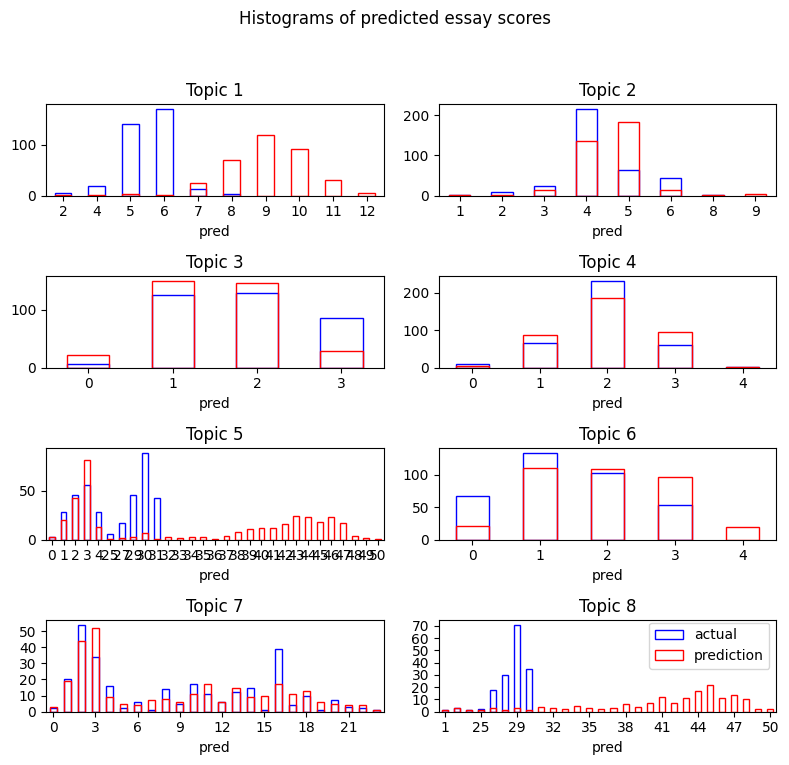

In [100]:
## Histograms of Predicted Essay Scores for Each Topic
topic_number = 0
fig, ax = plt.subplots(4,2, figsize=(8,8), sharey=False)
for i in range(4):
    for j in range(2):
        results[results['topic'] == topic_names[topic_number]]\
            .groupby('y_true')['y_true']\
            .agg('count')\
            .plot.bar(ax=ax[i, j], rot=0, fill=False, ec='b', label='actual')
        results[results['topic'] == topic_names[topic_number]]\
            .groupby('pred')['pred']\
            .agg('count')\
            .plot.bar(ax=ax[i, j], rot=0, fill=False, ec='r', label='prediction')
        topic_number += 1
        ax[i,j].set_title('Topic %i' % topic_number)
ax[3,0].locator_params(nbins=10)
ax[3,1].locator_params(nbins=10)
plt.suptitle('Histograms of predicted essay scores')
plt.legend(bbox_to_anchor=(1.0, 1.05))
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [104]:
print(estimator.history.keys())

dict_keys(['loss', 'mae', 'mse'])


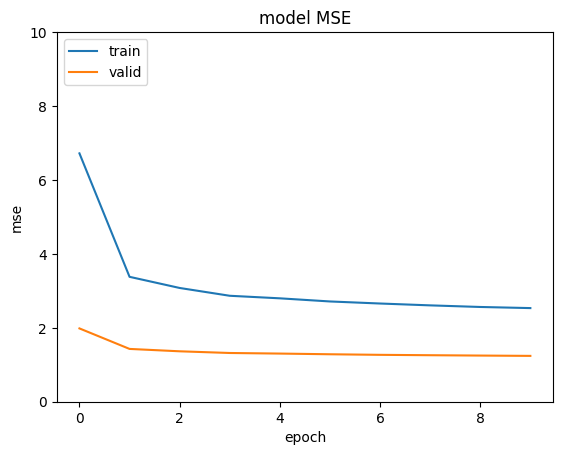

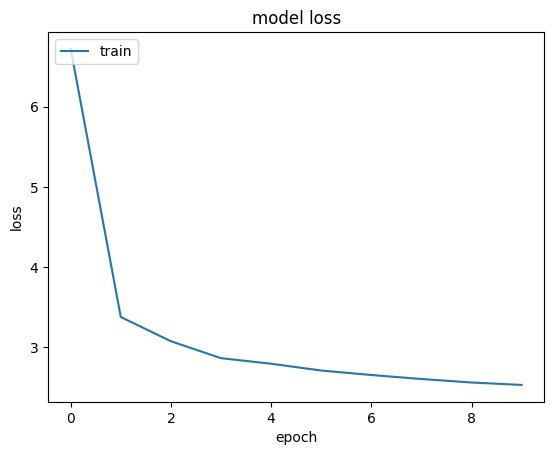

In [106]:
# Plot model mse over epochs
sns.reset_orig()   # Reset seaborn settings to get rid of black background
plt.plot(estimator.history['mse'])
plt.plot(estimator.history['mae'])
plt.title('model MSE')
plt.ylabel('mse')
plt.xlabel('epoch')
plt.legend(['train', 'valid'], loc='upper left')
plt.ylim(0,10)
plt.show()

# Plot model loss over epochs
plt.plot(estimator.history['loss'])
#plt.plot(estimator.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'valid'], loc='upper left')
plt.show()

In [107]:
# Calculate the number of scaling errors
errors_df = results.query('y_true != target_score')[['topic', 'target_score', 'y_true']]
error_percentage = len(errors_df) / results.shape[0] * 100

print('{:.1f}% of target scores did not revert back to their original value.'.format(error_percentage))


70.5% of target scores did not revert back to their original value.
